# Trabalho 4 — Aprendizagem de Máquina Probabilística
**Aluno:** Tiago Oliveria Lima  
**Matrícula:** 564988


## Preparação e reprodutibilidade

In [ ]:
import platform
import time
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy.special import digamma, gammaln
from scipy.stats import norm, gamma, t as student_t
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

SEED = 564988
# Limita paralelismo para evitar sobrecarga nas matrizes pequenas do espaço latente.
blas_limit = threadpool_limits(limits=2, user_api='blas')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': False})
pd.set_option('display.precision', 6)

print(f'Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__}')
print(f'Pandas {pd.__version__} | Matplotlib {matplotlib.__version__} | semente {SEED}')

Python 3.12.10 | NumPy 2.5.1 | SciPy 1.18.0
Pandas 3.0.3 | Matplotlib 3.10.8 | semente 564988


## 1. PPCA para os dígitos 5 do MNIST

### 1.1 Modelo e algoritmo EM

$$
z_i\sim\mathcal N(0,I_L),\qquad
x_i\mid z_i\sim\mathcal N(\mu+Wz_i,\sigma^2 I_D),
\qquad p(x_i)=\mathcal N(\mu,WW^T+\sigma^2 I_D).
$$

Aqui, $D=784$, $L<D$, $W\in\mathbb R^{D\times L}$ e $\sigma^2>0$. A média $\mu$ é estimada pela média de treino. Definindo $y_i=x_i-\mu$ e $M=W^TW+\sigma^2 I_L$, o **passo E** calcula

$$
\mathbb E[z_i]=M^{-1}W^Ty_i,\qquad
\mathbb E[z_i z_i^T]=\sigma^2M^{-1}+\mathbb E[z_i]\mathbb E[z_i]^T.
$$

No **passo M**, os momentos acima são mantidos fixos e atualizamos

$$
W_{novo}=\left(\sum_i y_i\mathbb E[z_i]^T\right)
         \left(\sum_i\mathbb E[z_i z_i^T]\right)^{-1},
$$

$$
\sigma^2_{novo}=\frac1{ND}\left[\sum_i\|y_i\|^2
-2\sum_i\mathbb E[z_i]^TW_{novo}^Ty_i
+\operatorname{tr}\left(\sum_i\mathbb E[z_i z_i^T]W_{novo}^TW_{novo}\right)\right].
$$

A implementação usa essas mesmas equações por meio de estatísticas suficientes: $S=Y^TY/N$, $B=WM^{-1}$, $C_{xz}=SB$ e $C_{zz}=\sigma^2M^{-1}+B^TSB$. Assim, $W_{novo}=C_{xz}C_{zz}^{-1}$ e $\sigma^2_{novo}=[\operatorname{tr}(S)-2\operatorname{tr}(W_{novo}^TC_{xz})+\operatorname{tr}(C_{zz}W_{novo}^TW_{novo})]/D$. Isso evita percorrer todas as imagens a cada iteração, sem substituir o EM por PCA/SVD.

Monitoramos a log-verossimilhança marginal média de treino. A identidade de Woodbury e o lema do determinante reduzem a álgebra a matrizes $L\times L$:

$$
\log|WW^T+\sigma^2I_D|=(D-L)\log\sigma^2+\log|M|,
\quad
\operatorname{tr}(C^{-1}S)=\frac{\operatorname{tr}(S)-\operatorname{tr}(M^{-1}W^TSW)}{\sigma^2}.
$$

Utilizamos sistemas lineares em vez de inversões explícitas. A parada exige variação relativa da log-verossimilhança menor que $10^{-8}$ ou, no máximo, 2.000 iterações; o estado de convergência é reportado.

Dados: (6313, 784); faixa original: [0, 255]
Treino: 5050 | Teste: 1263 | pixels reescalados para [0, 1]


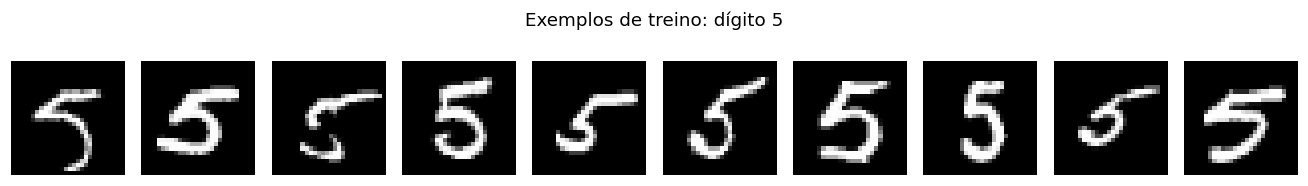

In [26]:
X_bruto = np.loadtxt('mnist_5.csv', delimiter=',', dtype=np.float64)

assert X_bruto.shape == (6313, 784)
assert np.isfinite(X_bruto).all() and 0 <= X_bruto.min() <= X_bruto.max() <= 255

X = X_bruto / 255.0  # escala fixa, sem aprender estatísticas a partir do teste

rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X))
n_teste = int(np.ceil(0.2 * len(X)))
idx_teste, idx_treino = indices[:n_teste], indices[n_teste:]
X_treino, X_teste = X[idx_treino], X[idx_teste]
assert not np.intersect1d(idx_treino, idx_teste).size

print(f'Dados: {X.shape}; faixa original: [{X_bruto.min():.0f}, {X_bruto.max():.0f}]')
print(f'Treino: {len(X_treino)} | Teste: {len(X_teste)} | pixels reescalados para [0, 1]')
fig, axes = plt.subplots(1, 10, figsize=(12, 1.7))
for ax, imagem in zip(axes, X_treino[:10]):
    ax.imshow(imagem.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
fig.suptitle('Exemplos de treino: dígito 5')
plt.tight_layout()
plt.show()

In [27]:
class PPCA_EM:
    """PPCA com ruído isotrópico e treinamento EM por estatísticas suficientes."""
    def __init__(self, latent_dim, max_iter=2000, tol=1e-8, seed=SEED):
        self.latent_dim = latent_dim
        self.max_iter = max_iter
        self.tol = tol
        self.seed = seed

    def _loglik_cov(self, S, W, sigma2):
        d, l = W.shape
        M = W.T @ W + sigma2 * np.eye(l)
        sign, logdet_M = np.linalg.slogdet(M)
        assert sign > 0
        logdet_C = (d - l) * np.log(sigma2) + logdet_M
        quadratic = (np.trace(S) - np.trace(np.linalg.solve(M, W.T @ S @ W))) / sigma2
        return -0.5 * (d * np.log(2 * np.pi) + logdet_C + quadratic)

    def fit(self, X):
        n, d = X.shape
        l = self.latent_dim
        if not 0 < l < d:
            raise ValueError('A dimensão latente deve estar entre 1 e D-1.')
        self.mean_ = X.mean(axis=0)
        Y = X - self.mean_
        S = Y.T @ Y / n
        total_var = np.trace(S)
        rng = np.random.default_rng(self.seed)
        W = rng.normal(0, np.sqrt(total_var / (d * l)), size=(d, l))
        sigma2 = total_var / d
        self.history_ = [self._loglik_cov(S, W, sigma2)]
        self.converged_ = False
        for iteration in range(1, self.max_iter + 1):
            # E: todos os momentos usam W e sigma² da iteração anterior.
            M = W.T @ W + sigma2 * np.eye(l)
            B = np.linalg.solve(M, W.T).T
            Cxz = S @ B
            Czz = sigma2 * np.linalg.solve(M, np.eye(l)) + B.T @ Cxz
            # M: atualiza W e depois sigma² com os momentos fixos do passo E.
            W_new = np.linalg.solve(Czz, Cxz.T).T
            sigma2_new = (total_var - 2 * np.sum(W_new * Cxz)
                          + np.trace(Czz @ (W_new.T @ W_new))) / d
            sigma2_new = max(float(sigma2_new), 1e-10)
            ll = self._loglik_cov(S, W_new, sigma2_new)
            old_ll = self.history_[-1]
            if ll < old_ll - 1e-7 * max(1, abs(old_ll)):
                raise ArithmeticError('A log-verossimilhança diminuiu além da tolerância numérica.')
            self.history_.append(ll)
            W, sigma2 = W_new, sigma2_new
            if abs(ll - old_ll) <= self.tol * max(1, abs(old_ll)):
                self.converged_ = True
                break
        self.W_, self.sigma2_, self.n_iter_ = W, sigma2, iteration
        if not self.converged_:
            warnings.warn(f'PPCA L={l}: limite de iterações atingido.')
        return self

    def transform(self, X):
        M = self.W_.T @ self.W_ + self.sigma2_ * np.eye(self.latent_dim)
        return np.linalg.solve(M, self.W_.T @ (X - self.mean_).T).T

    def reconstruct(self, X):
        return self.transform(X) @ self.W_.T + self.mean_

    def score(self, X):
        Y = X - self.mean_
        return self._loglik_cov(Y.T @ Y / len(Y), self.W_, self.sigma2_)

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        z = rng.standard_normal((n, self.latent_dim))
        media_condicional = self.mean_ + z @ self.W_.T
        amostra = media_condicional + rng.normal(0, np.sqrt(self.sigma2_), media_condicional.shape)
        return media_condicional, amostra

### 1.2 Protocolo de avaliação
Usamos 80% das imagens para treino e 20% para teste, com a mesma divisão para $L\in\{2,10,20\}$. A normalização por 255 preserva o contraste relativo dos pixels. Cada configuração é treinada com duas inicializações aleatórias. A escolha usa **somente a maior log-verossimilhança final de treino**. O teste não participa da escolha da inicialização.

A reconstrução é $\hat x_i=\mu+W\mathbb E[z_i\mid x_i]$. Reportamos MSE por pixel, RMSE e log-densidade marginal média. O baseline reconstrói todas as imagens com a média de treino. Os erros são calculados com as saídas reais do modelo, sem recorte para $[0,1]$. A log-densidade pode ser positiva, pois se trata de densidade contínua na escala normalizada, e não de uma probabilidade discreta.

Baseline (imagem média de treino), MSE teste = 0.060909


,L,inicialização,iterações,convergiu,log-densidade treino,segundos
0,2,1,746,True,99.647614,1.062719
1,2,2,679,True,99.647614,0.922070
2,10,1,837,True,276.046350,1.587395
3,10,2,841,True,276.046352,1.687718
4,20,1,1002,True,401.706781,2.472716
5,20,2,984,True,401.706782,2.318360


,iterações,convergiu,sigma²,MSE treino,MSE teste,RMSE teste,redução MSE vs. média (%),log-densidade teste
L,,,,,,,,
2,679,True,0.044844,0.044730,0.044840,0.211754,26.382601,98.680377
10,841,True,0.027397,0.027053,0.027286,0.165186,55.201874,272.722550
20,984,True,0.018913,0.018440,0.018753,0.136941,69.211880,395.275583


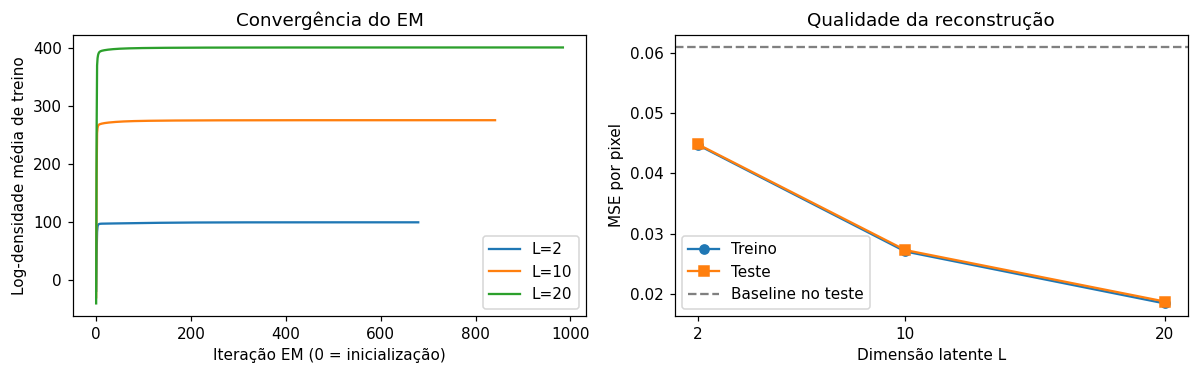

In [28]:
dimensoes = [2, 10, 20]
modelos, execucoes, linhas = {}, [], []
baseline_mse = np.mean((X_teste - X_treino.mean(axis=0)) ** 2)
for l in dimensoes:
    candidatos_l = []
    for tentativa in range(2):
        inicio = time.perf_counter()
        modelo = PPCA_EM(l, seed=SEED + tentativa).fit(X_treino)
        candidatos_l.append(modelo)
        execucoes.append({'L': l, 'inicialização': tentativa + 1,
                          'iterações': modelo.n_iter_, 'convergiu': modelo.converged_,
                          'log-densidade treino': modelo.history_[-1],
                          'segundos': time.perf_counter() - inicio})
    modelo = max(candidatos_l, key=lambda m: m.history_[-1])
    modelos[l] = modelo
    mse_treino = np.mean((X_treino - modelo.reconstruct(X_treino)) ** 2)
    mse_teste = np.mean((X_teste - modelo.reconstruct(X_teste)) ** 2)
    linhas.append({'L': l, 'iterações': modelo.n_iter_, 'convergiu': modelo.converged_,
                   'sigma²': modelo.sigma2_, 'MSE treino': mse_treino,
                   'MSE teste': mse_teste, 'RMSE teste': np.sqrt(mse_teste),
                   'redução MSE vs. média (%)': 100 * (1 - mse_teste / baseline_mse),
                   'log-densidade teste': modelo.score(X_teste)})
resultados_ppca = pd.DataFrame(linhas).set_index('L')
print(f'Baseline (imagem média de treino), MSE teste = {baseline_mse:.6f}')
display(pd.DataFrame(execucoes))
display(resultados_ppca)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for l, modelo in modelos.items():
    axes[0].plot(modelo.history_, label=f'L={l}')
axes[0].set(xlabel='Iteração EM (0 = inicialização)', ylabel='Log-densidade média de treino',
            title='Convergência do EM')
axes[0].legend()
axes[1].plot(dimensoes, resultados_ppca['MSE treino'], 'o-', label='Treino')
axes[1].plot(dimensoes, resultados_ppca['MSE teste'], 's-', label='Teste')
axes[1].axhline(baseline_mse, color='gray', ls='--', label='Baseline no teste')
axes[1].set(xlabel='Dimensão latente L', ylabel='MSE por pixel', title='Qualidade da reconstrução', xticks=dimensoes)
axes[1].legend()
plt.tight_layout()
plt.show()

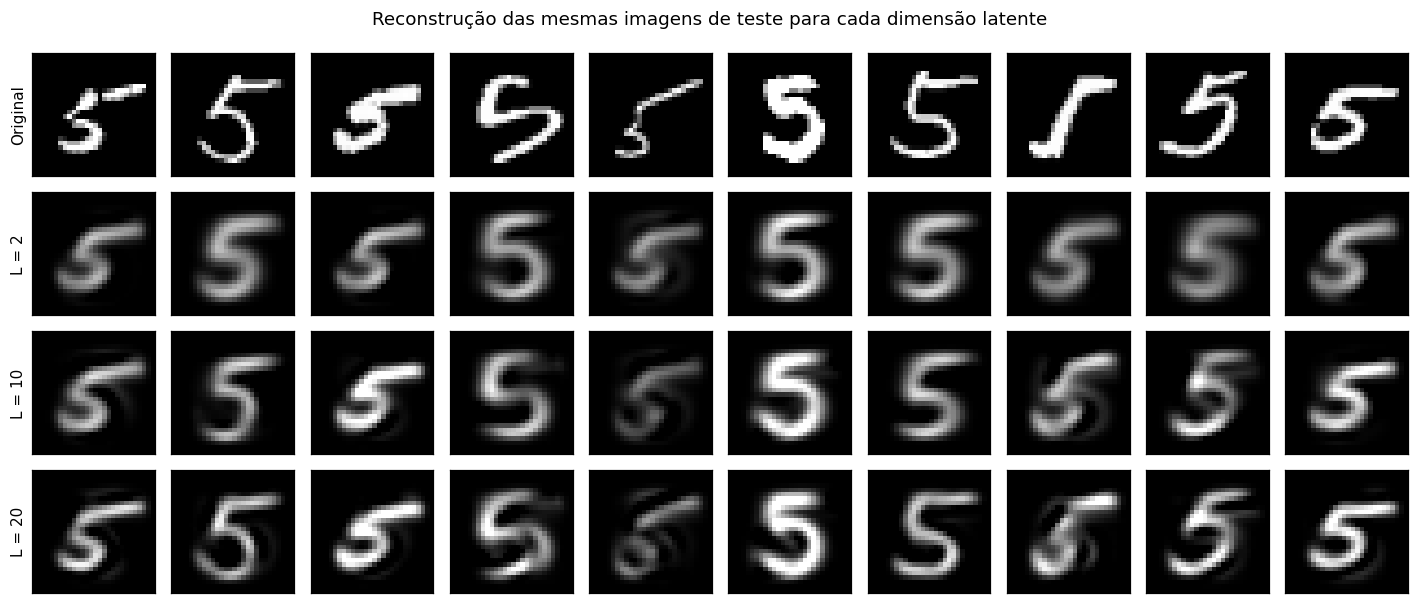

In [29]:
n_exemplos = 10
fig, axes = plt.subplots(4, n_exemplos, figsize=(13, 5.6))
colecoes = [('Original', X_teste[:n_exemplos])] + [
    (f'L = {l}', modelos[l].reconstruct(X_teste[:n_exemplos])) for l in dimensoes]
for i, (rotulo, imagens) in enumerate(colecoes):
    for j, imagem in enumerate(imagens):
        axes[i, j].imshow(imagem.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(rotulo)
fig.suptitle('Reconstrução das mesmas imagens de teste para cada dimensão latente')
plt.tight_layout()
plt.show()

### 1.3 Geração de novos dígitos
Para gerar uma nova imagem, sorteamos $z\sim\mathcal N(0,I_L)$ e $\epsilon\sim\mathcal N(0,\sigma^2I_D)$ e calculamos $x=\mu+Wz+\epsilon$. Mostramos tanto a **média condicional** $\mu+Wz$ quanto a **amostra completa**, que inclui o ruído. Apenas a segunda é uma amostra de $p(x)$. Para cada par de linhas, usamos o mesmo $z$, permitindo visualizar o efeito do ruído.

O modelo Gaussiano tem suporte em $\mathbb R^{784}$, portanto pode gerar intensidades fora de $[0,1]$. Os gráficos saturam esses valores para visualização com `vmin=0, vmax=1`; as amostras e métricas não são modificadas. A fração de pixels fora do intervalo é reportada como limitação do modelo.

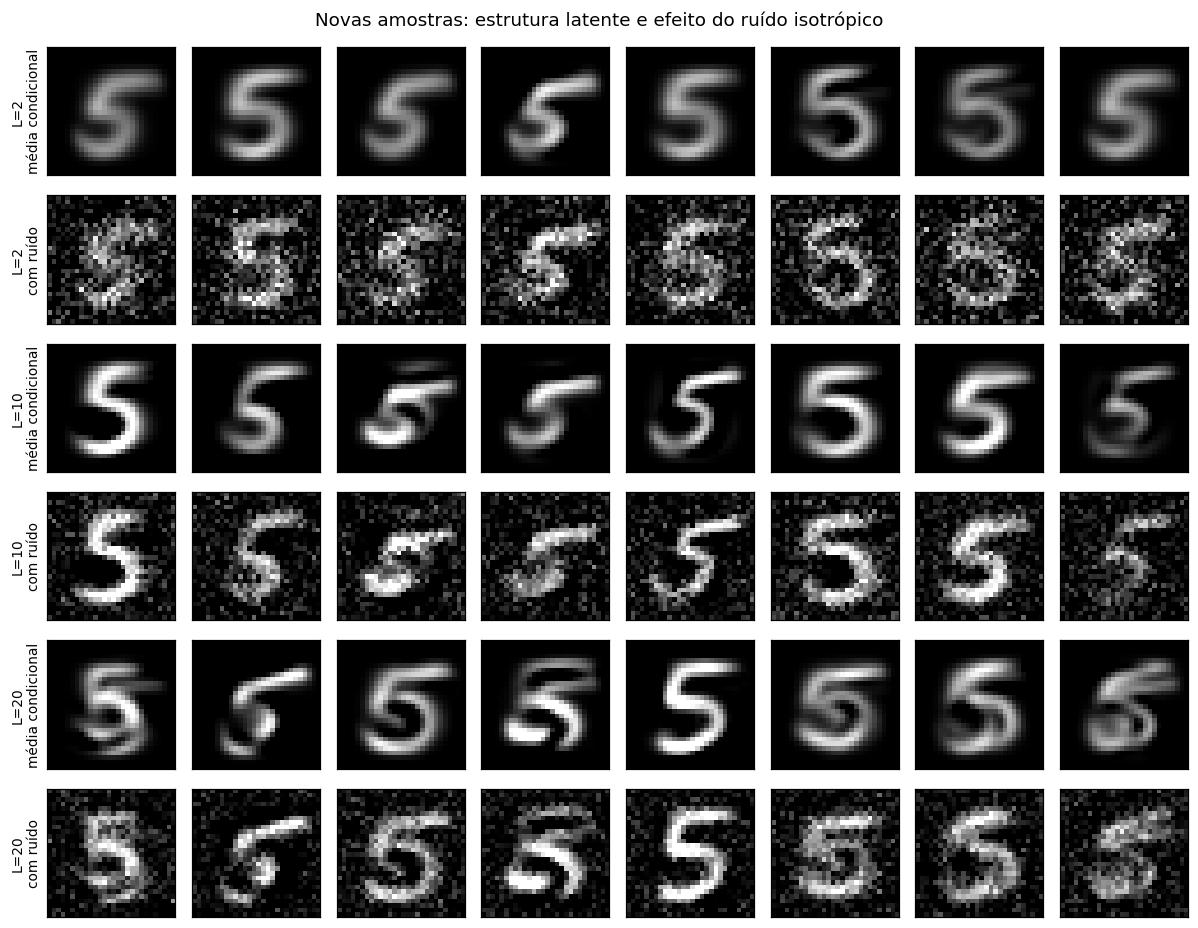

,"pixels gerados fora de [0,1] (%)"
L,
2,36.383929
10,41.980230
20,38.345026


**Leitura dos resultados:** entre as dimensões avaliadas, L=20 apresentou o menor MSE de teste (0.018753), contra 0.060909 do baseline. Esse resultado descreve a comparação; não foi usado para reajustar os modelos.

In [30]:
fig, axes = plt.subplots(6, 8, figsize=(11, 8.6))
geracao = []
for i, l in enumerate(dimensoes):
    medias, amostras = modelos[l].sample(8, seed=SEED + 100 + l)
    geracao.append({'L': l, 'pixels gerados fora de [0,1] (%)':
                     100 * np.mean((amostras < 0) | (amostras > 1))})
    for offset, (rotulo, imagens) in enumerate([('média condicional', medias), ('com ruído', amostras)]):
        for j, imagem in enumerate(imagens):
            ax = axes[2*i + offset, j]
            ax.imshow(imagem.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(f'L={l}\n{rotulo}', fontsize=9)
fig.suptitle('Novas amostras: estrutura latente e efeito do ruído isotrópico')
plt.tight_layout()
plt.show()
display(pd.DataFrame(geracao).set_index('L'))
best_l = resultados_ppca['MSE teste'].idxmin()
display(Markdown(
    f'**Leitura dos resultados:** entre as dimensões avaliadas, L={best_l} apresentou '
    f'o menor MSE de teste ({resultados_ppca.loc[best_l, "MSE teste"]:.6f}), '
    f'contra {baseline_mse:.6f} do baseline. '
    'Esse resultado descreve a comparação; não foi usado para reajustar os modelos.'))

### 1.4 Discussão do PPCA
A comparação das reconstruções permite observar como um espaço latente pequeno privilegia características globais do dígito e como mais dimensões podem representar detalhes de traço e inclinação. A tabela de MSE quantifica essa comparação fora do treino, a diferença entre os erros de treino e de teste ajuda a avaliar a generalização.

A geração deve ser interpretada separadamente da reconstrução: um modelo capaz de reconstruir melhor as imagens observadas não necessariamente produz novos dígitos visualmente melhores. O PPCA continua sendo um modelo **linear e unimodal**; não representa integralmente a variedade de formatos manuscritos. O ruído isotrópico também afeta pixels de fundo, produzindo granulação. A inspeção visual e a fração de intensidades fora do intervalo são diagnósticos descritivos de geração, sem pretender medir automaticamente a legibilidade dos dígitos.

**Resultados observados nesta execução.** O MSE de teste caiu de **0,044840** (L=2) para **0,027286** (L=10) e **0,018753** (L=20). Em relação à imagem média, as reduções foram, respectivamente, **26,38%**, **55,20%** e **69,21%**. Os erros de treino foram próximos dos de teste nas três configurações. Na grade de reconstrução, L=2 aproxima diferentes formas por um 5 relativamente parecido e borrado; L=20 preserva melhor diferenças de inclinação, largura e fechamento do traço, embora ainda suavize detalhes.

Nas imagens geradas, as médias condicionais apresentam estruturas semelhantes a dígitos 5, mas algumas amostras são deformadas ou têm traços incompletos. A adição do ruído deixa o fundo granulado nas três dimensões. Cerca de **36% a 42%** dos pixels das pequenas grades geradas ficaram fora de [0,1], reforçando a limitação do suporte Gaussiano para intensidades de imagem. Essa proporção é descritiva das oito amostras mostradas por modelo. As duas inicializações de cada configuração convergiram; o modelo selecionado exigiu 679, 841 e 984 iterações para L=2, 10 e 20, respectivamente.

## 2. Inferência variacional para a Gaussiana univariada

### 2.1 Modelo, priori e família variacional
O modelo e a priori são

$$
x_i\mid\mu,\tau\sim\mathcal N(\mu,\tau^{-1}),\qquad
p(\mu,\tau)=\mathcal N(\mu\mid\mu_0,(\kappa_0\tau)^{-1})\operatorname{Gamma}(\tau\mid a_0,b_0).
$$

$\tau$ é a **precisão**, o inverso da variância. Adotamos Gamma na parametrização **forma–taxa**:

$$
p(\tau)=\frac{b_0^{a_0}}{\Gamma(a_0)}\tau^{a_0-1}e^{-b_0\tau},\quad \mathbb E[\tau]=a_0/b_0.
$$

O enunciado não fixa os hiperparâmetros. Escolhemos, antes dos experimentos, $\mu_0=0$, $\kappa_0=0{,}01$ e $a_0=b_0=1$. A priori de $\tau$ é uma exponencial de média 1, relativamente dispersa, e o pequeno $\kappa_0$ dá pouco peso à média a priori. São prioris próprias e idênticas em todos os tamanhos amostrais; não são estimadas com os 500 dados. No SciPy, a taxa $b$ corresponde a `scale=1/b`.

A aproximação mean field impõe independência:

$$
p(\mu,\tau\mid x)\approx q_\mu(\mu)q_\tau(\tau),\quad
q_\mu=\mathcal N(m,\lambda^{-1}),\quad q_\tau=\operatorname{Gamma}(a,b).
$$

Escrevemos $\lambda$ para a precisão de $q_\mu$ (chamada $\kappa_N$ nos slides), distinguindo-a de $\kappa_0+N$.

Maximizamos $\mathcal L(q)=\mathbb E_q[\log p(x,\mu,\tau)]+H(q_\mu)+H(q_\tau)$, equivalente a minimizar $\mathrm{KL}(q\|p)$. As atualizações coordenadas são

$$
m=\frac{\kappa_0\mu_0+\sum_i x_i}{\kappa_0+N},\qquad
 a=a_0+\frac{N+1}{2},
$$

$$
\lambda=(\kappa_0+N)\frac{a}{b},\qquad
b=b_0+\frac12\left[\kappa_0\big((m-\mu_0)^2+\lambda^{-1}\big)
+\sum_i\big((x_i-m)^2+\lambda^{-1}\big)\right].
$$

Em particular, o termo $+1$ em $a$ vem da normalização da priori condicional $p(\mu\mid\tau)$. Ele deve ser mantido. Os valores pedidos são $\mathbb E_q[\mu]=m$ e $\mathbb E_q[\tau]=a/b$. Também temos $\operatorname{Var}_q(\mu)=1/\lambda$ e $\operatorname{Var}_q(\tau)=a/b^2$.

### 2.2 ELBO e convergência
Para $v=1/\lambda$, $T=a/b$ e $U=\psi(a)-\log b$, usamos

$$
\begin{aligned}
\mathcal L={}&\frac N2(U-\log 2\pi)-\frac T2\sum_i[(x_i-m)^2+v]\\
&+\frac12[\log\kappa_0+U-\log 2\pi]
-\frac{\kappa_0T}{2}[(m-\mu_0)^2+v]\\
&+a_0\log b_0-\log\Gamma(a_0)+(a_0-1)U-b_0T\\
&+\frac12\log(2\pi e v)+a-\log b+\log\Gamma(a)+(1-a)\psi(a).
\end{aligned}
$$

Cada ciclo atualiza $q_\mu$ e depois $q_\tau$, guardando o ELBO do par resultante. A parada exige estabilidade relativa de $\lambda$, $b$ e do ELBO. Cada experimento parte da mesma inicialização; não reutilizamos a posteriori de um prefixo como priori do próximo, pois isso contaria observações novamente.

Observações: 500 | média: 1.972675 | variância ML: 0.503208


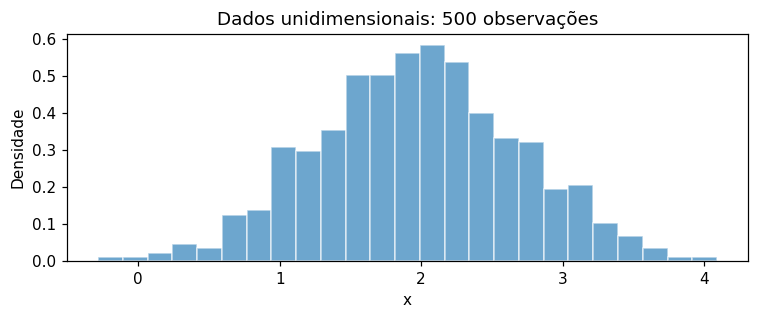

In [31]:
dados_1d = np.loadtxt('gaussian_1d.csv', delimiter=',', dtype=np.float64).reshape(-1)
assert dados_1d.shape == (500,) and np.isfinite(dados_1d).all()
MU0, KAPPA0, A0, B0 = 0.0, 0.01, 1.0, 1.0
print(f'Observações: {len(dados_1d)} | média: {dados_1d.mean():.6f} | variância ML: {dados_1d.var():.6f}')
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(dados_1d, bins=25, density=True, alpha=0.65, edgecolor='white')
ax.set(xlabel='x', ylabel='Densidade', title='Dados unidimensionais: 500 observações')
plt.tight_layout()
plt.show()

In [32]:
def elbo_gaussiana(x, m, lam, a, b, mu0=MU0, kappa0=KAPPA0, a0=A0, b0=B0):
    n = len(x)
    v = 1 / lam
    etau, elogtau = a / b, digamma(a) - np.log(b)
    residuo = np.sum((x - m) ** 2) + n * v
    log_lik = 0.5 * n * (elogtau - np.log(2 * np.pi)) - 0.5 * etau * residuo
    log_prior_mu = 0.5 * (np.log(kappa0) + elogtau - np.log(2 * np.pi))
    log_prior_mu -= 0.5 * kappa0 * etau * ((m - mu0) ** 2 + v)
    log_prior_tau = (a0 * np.log(b0) - gammaln(a0)
                     + (a0 - 1) * elogtau - b0 * etau)
    h_mu = 0.5 * np.log(2 * np.pi * np.e * v)
    h_tau = a - np.log(b) + gammaln(a) + (1 - a) * digamma(a)
    return log_lik + log_prior_mu + log_prior_tau + h_mu + h_tau


def inferencia_variacional(x, mu0=MU0, kappa0=KAPPA0, a0=A0, b0=B0,
                           tol=1e-10, max_iter=10000):
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n == 0 or min(kappa0, a0, b0) <= 0 or not np.isfinite(x).all():
        raise ValueError('Dados finitos e hiperparâmetros positivos são necessários.')
    m = (kappa0 * mu0 + x.sum()) / (kappa0 + n)
    a = a0 + (n + 1) / 2
    lam, b = 1.0, 1.0
    base = b0 + 0.5 * (kappa0 * (m - mu0) ** 2 + np.sum((x - m) ** 2))
    historico = [elbo_gaussiana(x, m, lam, a, b, mu0, kappa0, a0, b0)]
    convergiu = False
    for it in range(1, max_iter + 1):
        lam_anterior, b_anterior = lam, b
        lam = (kappa0 + n) * a / b  # atualização de q_mu
        b = base + 0.5 * (kappa0 + n) / lam  # atualização de q_tau
        elbo = elbo_gaussiana(x, m, lam, a, b, mu0, kappa0, a0, b0)
        if elbo < historico[-1] - 1e-8:
            raise ArithmeticError('O ELBO diminuiu além da tolerância numérica.')
        delta_elbo = abs(elbo - historico[-1]) / max(1, abs(historico[-1]))
        historico.append(elbo)
        delta_param = max(abs(lam / lam_anterior - 1), abs(b / b_anterior - 1))
        if max(delta_elbo, delta_param) < tol:
            convergiu = True
            break
    if not convergiu:
        warnings.warn('Inferência variacional: limite de iterações atingido.')
    return {'m': m, 'lam': lam, 'a': a, 'b': b, 'E_mu': m, 'E_tau': a / b,
            'sd_mu': np.sqrt(1 / lam), 'sd_tau': np.sqrt(a) / b,
            'historico': np.array(historico), 'iterações': it, 'convergiu': convergiu}

,E_q[mu],E_q[tau],DP q(mu),DP q(tau),IC95 mu inferior,IC95 mu superior,IC95 tau inferior,IC95 tau superior,iterações,convergiu
N,,,,,,,,,,
10,1.807616,1.240316,0.283803,0.486492,1.251372,2.363859,0.477879,2.359997,11,True
50,2.008983,1.389615,0.119957,0.269943,1.773872,2.244093,0.911806,1.966486,8,True
100,2.018967,1.552816,0.080245,0.216380,1.861690,2.176245,1.157958,2.004711,7,True
500,1.972635,1.979160,0.031789,0.124799,1.910331,2.034939,1.742095,2.231129,6,True


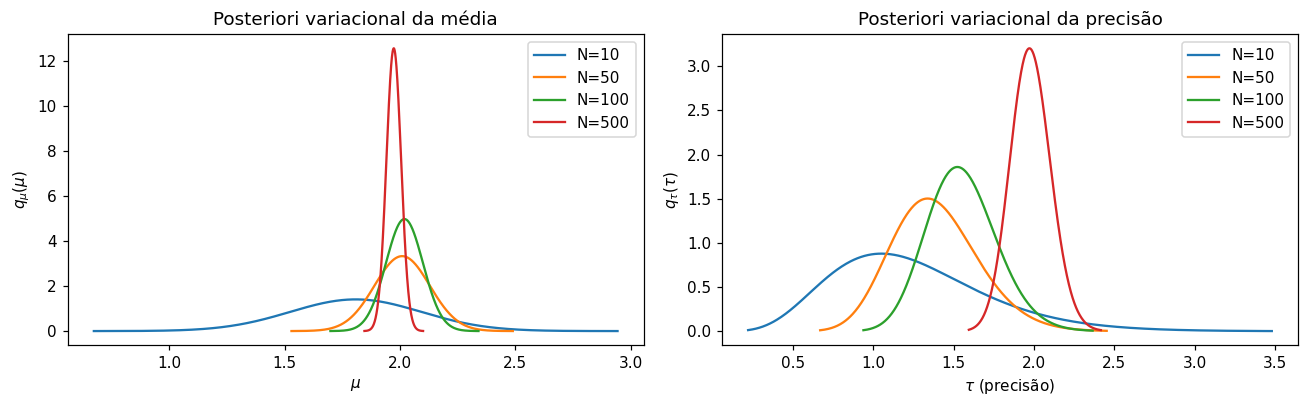

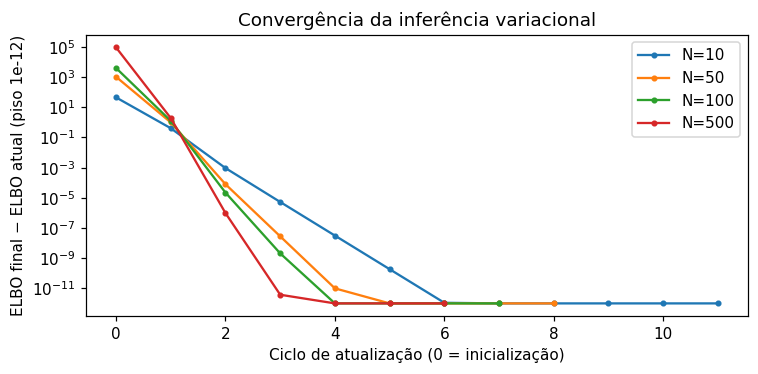

In [33]:
tamanhos = [10, 50, 100, 500]
posteriores, linhas_vi = {}, []
for n in tamanhos:
    r = inferencia_variacional(dados_1d[:n])  # exatamente os primeiros N pontos, sem embaralhar
    posteriores[n] = r
    ic_mu = norm.ppf([0.025, 0.975], loc=r['m'], scale=r['sd_mu'])
    ic_tau = gamma.ppf([0.025, 0.975], a=r['a'], scale=1 / r['b'])
    linhas_vi.append({'N': n, 'E_q[mu]': r['E_mu'], 'E_q[tau]': r['E_tau'],
                      'DP q(mu)': r['sd_mu'], 'DP q(tau)': r['sd_tau'],
                      'IC95 mu inferior': ic_mu[0], 'IC95 mu superior': ic_mu[1],
                      'IC95 tau inferior': ic_tau[0], 'IC95 tau superior': ic_tau[1],
                      'iterações': r['iterações'], 'convergiu': r['convergiu']})
resultados_vi = pd.DataFrame(linhas_vi).set_index('N')
display(resultados_vi)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for n, r in posteriores.items():
    grid_mu = np.linspace(r['m'] - 4*r['sd_mu'], r['m'] + 4*r['sd_mu'], 600)
    grid_tau = np.linspace(gamma.ppf(0.0005, r['a'], scale=1/r['b']),
                           gamma.ppf(0.9995, r['a'], scale=1/r['b']), 600)
    axes[0].plot(grid_mu, norm.pdf(grid_mu, r['m'], r['sd_mu']), label=f'N={n}')
    axes[1].plot(grid_tau, gamma.pdf(grid_tau, r['a'], scale=1/r['b']), label=f'N={n}')
axes[0].set(xlabel=r'$\mu$', ylabel=r'$q_\mu(\mu)$', title='Posteriori variacional da média')
axes[1].set(xlabel=r'$\tau$ (precisão)', ylabel=r'$q_\tau(\tau)$', title='Posteriori variacional da precisão')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 3.5))
for n, r in posteriores.items():
    gap = np.maximum(r['historico'][-1] - r['historico'], 1e-12)
    ax.semilogy(np.arange(len(gap)), gap, 'o-', markersize=3, label=f'N={n}')
ax.set(xlabel='Ciclo de atualização (0 = inicialização)', ylabel='ELBO final − ELBO atual (piso 1e-12)',
       title='Convergência da inferência variacional')
ax.legend()
plt.tight_layout()
plt.show()

### 2.3 Verificação com a posteriori conjugada exata
Neste exemplo didático, a posteriori Normal-Gamma exata é conhecida. Ela serve como verificação independente, **os resultados variacionais acima foram obtidos pelas atualizações iterativas**. Definindo

$$
K=\kappa_0+N,\quad A=a_0+N/2,\quad
B=b_0+\tfrac12\sum_i(x_i-\bar x)^2+
\frac{\kappa_0N}{2K}(\bar x-\mu_0)^2,
$$

obtemos $p(\tau\mid x)=\operatorname{Gamma}(A,B)$ e $p(\mu\mid x)=t_{2A}(m,\sqrt{B/(AK)})$, em que o segundo argumento é a escala da Student. A evidência é

$$
\log p(x)=-\frac N2\log(2\pi)+\frac12\log(\kappa_0/K)
+a_0\log b_0-A\log B+\log\Gamma(A)-\log\Gamma(a_0).
$$

No ponto fixo variacional, $a=A+1/2$, $b=B\,a/A$ e $\lambda=KA/B$. Logo, as médias de $\mu$ e $\tau$ coincidem com as exatas neste modelo, mas as distribuições não: a variância variacional de $\mu$ é $B/(AK)$, enquanto a exata é $B/[(A-1)K]$ para $A>1$. A variância variacional de $\tau$ também é menor: $A^2/(aB^2)$ em vez de $A/B^2$.

Portanto, igualdade de médias não demonstra igualdade de posterioris. O produto mean field remove a dependência entre os parâmetros e subestima sua incerteza. A diferença $\log p(x)-\mathcal L(q)$ é a divergência KL para a posteriori conjunta exata.

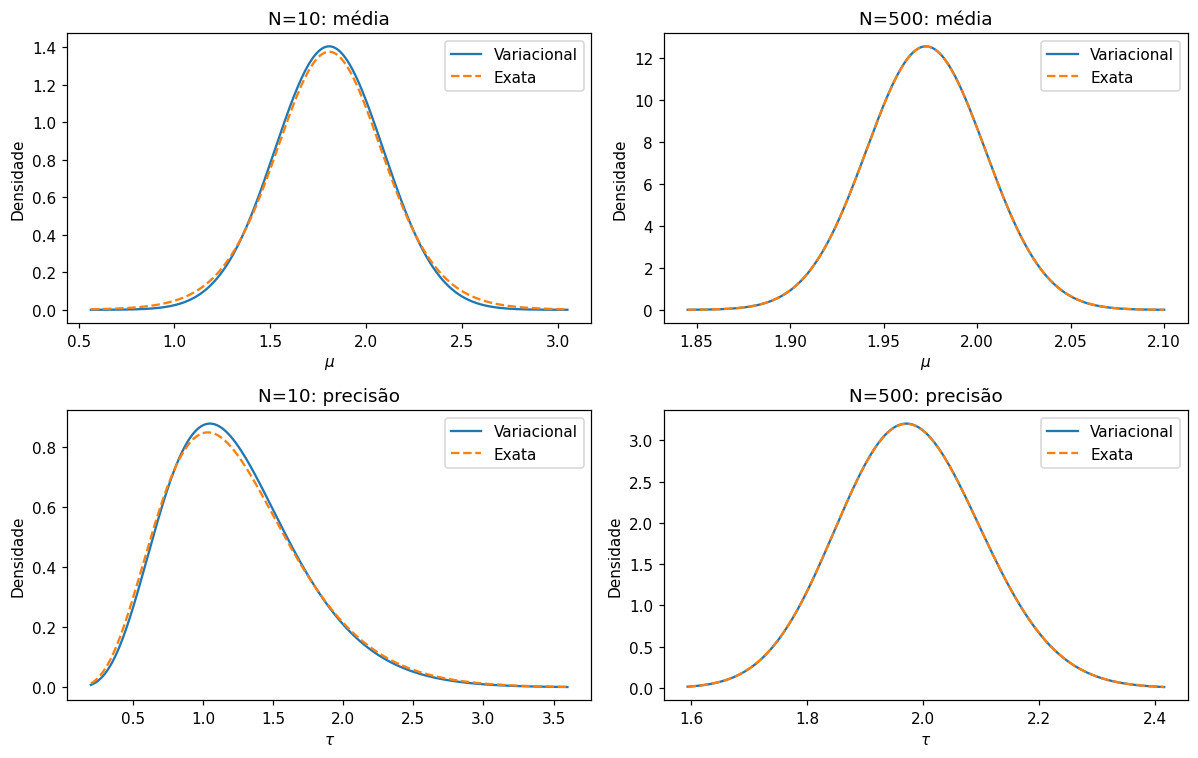

,E exata[tau],Var q(mu) / Var exata(mu),Var q(tau) / Var exata(tau),ELBO final,log evidência,KL(q || posteriori)
N,,,,,,
10,1.240316,0.833333,0.923077,-17.355719,-17.314632,0.041087
50,1.389615,0.961538,0.981132,-68.367412,-68.357828,0.009585
100,1.552816,0.980392,0.990291,-126.105720,-126.100826,0.004894
500,1.979160,0.996016,0.998012,-546.372764,-546.371768,0.000996


In [34]:
comparacao = []
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, n in enumerate([10, 500]):
    r = posteriores[n]
    xn = dados_1d[:n]
    K, A = KAPPA0 + n, A0 + n / 2
    B = B0 + 0.5 * np.sum((xn - xn.mean()) ** 2) + KAPPA0*n/(2*K)*(xn.mean()-MU0)**2
    escala_mu = np.sqrt(B / (A*K))
    g_mu = np.linspace(r['m'] - 4*np.sqrt(B/((A-1)*K)), r['m'] + 4*np.sqrt(B/((A-1)*K)), 600)
    g_tau = np.linspace(gamma.ppf(0.0005, A, scale=1/B), gamma.ppf(0.9995, A, scale=1/B), 600)
    axes[0, col].plot(g_mu, norm.pdf(g_mu, r['m'], r['sd_mu']), label='Variacional')
    axes[0, col].plot(g_mu, student_t.pdf(g_mu, df=2*A, loc=r['m'], scale=escala_mu), '--', label='Exata')
    axes[0, col].set(title=f'N={n}: média', xlabel=r'$\mu$', ylabel='Densidade')
    axes[1, col].plot(g_tau, gamma.pdf(g_tau, r['a'], scale=1/r['b']), label='Variacional')
    axes[1, col].plot(g_tau, gamma.pdf(g_tau, A, scale=1/B), '--', label='Exata')
    axes[1, col].set(title=f'N={n}: precisão', xlabel=r'$\tau$', ylabel='Densidade')
for ax in axes.flat:
    ax.legend()
plt.tight_layout()
plt.show()

for n, r in posteriores.items():
    xn = dados_1d[:n]
    K, A = KAPPA0 + n, A0 + n/2
    B = B0 + 0.5*np.sum((xn-xn.mean())**2) + KAPPA0*n/(2*K)*(xn.mean()-MU0)**2
    log_evidencia = (-n/2*np.log(2*np.pi) + 0.5*np.log(KAPPA0/K)
                     + A0*np.log(B0) - A*np.log(B) + gammaln(A) - gammaln(A0))
    assert np.isclose(r['E_tau'], A/B, rtol=1e-8)
    assert np.isclose(r['lam'], K*A/B, rtol=1e-8)
    assert np.isclose(r['b'], B*r['a']/A, rtol=1e-8)
    assert np.all(np.diff(r['historico']) >= -1e-8)
    assert r['convergiu'] and log_evidencia >= r['historico'][-1] - 1e-8
    comparacao.append({'N': n, 'E exata[tau]': A/B,
                       'Var q(mu) / Var exata(mu)': (A-1)/A,
                       'Var q(tau) / Var exata(tau)': A/r['a'],
                       'ELBO final': r['historico'][-1],
                       'log evidência': log_evidencia,
                       'KL(q || posteriori)': log_evidencia-r['historico'][-1]})
display(pd.DataFrame(comparacao).set_index('N'))

In [35]:
r = posteriores[500]
display(Markdown(
    fr'**Resultado com todos os dados:** $\mathbb{{E}}_q[\mu]={r["E_mu"]:.6f}$ e '
    fr'$\mathbb{{E}}_q[\tau]={r["E_tau"]:.6f}$. '
    f'Os desvios-padrão variacionais são {r["sd_mu"]:.6f} para a média '
    f'e {r["sd_tau"]:.6f} para a precisão.'))

**Resultado com todos os dados:** $\mathbb{E}_q[\mu]=1.972635$ e $\mathbb{E}_q[\tau]=1.979160$. Os desvios-padrão variacionais são 0.031789 para a média e 0.124799 para a precisão.

### 2.4 Discussão da inferência variacional
Os quatro experimentos usam exatamente os primeiros 10, 50, 100 e 500 valores do arquivo. As curvas mostram o efeito do tamanho amostral sobre a localização e a concentração das posterioris, as tabelas explicitam as médias e os intervalos de credibilidade variacionais de 95%. Intervalos variacionais descrevem a incerteza da aproximação, que pode ser menor que a da posteriori exata.

Com mais observações, a influência da priori tende a diminuir e a incerteza tende a se reduzir. Os centros das distribuições podem mudar entre prefixos porque novos valores alteram a média e a dispersão amostrais, não há garantia de redução estritamente monótona da incerteza em toda sequência possível. A comparação exata mostra por que a diferença entre as distribuições fica menos perceptível com muitos dados.

Não se deve confundir $\mathbb E_q[\tau]$ com a variância dos dados: $\tau$ é precisão. Tampouco $1/\mathbb E_q[\tau]$ é, em geral, $\mathbb E_q[\tau^{-1}]$; para uma Gamma forma–taxa, esta última é $b/(a-1)$ quando $a>1$.

**Resultados observados nesta execução.** Para N=10, 50, 100 e 500, as médias aproximadas de μ foram **1,807616**, **2,008983**, **2,018967** e **1,972635**, e as médias da precisão τ foram **1,240316**, **1,389615**, **1,552816** e **1,979160**. A precisão estimada aumenta nesses prefixos, indicando menor dispersão inferida com a incorporação dos pontos restantes. O desvio-padrão de q(μ) caiu de **0,283803** para **0,031789**, enquanto o de q(τ) caiu de **0,486492** para **0,124799**.

Todos os experimentos convergiram, em 11, 8, 7 e 6 ciclos, respectivamente. A KL conjunta caiu de aproximadamente **0,041087** para **0,000996** entre N=10 e N=500. Para N=10, a variância de q(μ) equivale a 83,33% da exata; para N=500, essa razão é 99,60%. Assim, a subestimação de incerteza é mais perceptível no menor conjunto, apesar de as médias variacionais coincidirem com as médias exatas.